# 05 · Results and the shortlist

What the models are worth, what they are reading, and the ranked plant compounds that come out of
them. Nothing is fitted here: the models arrive tuned and calibrated from 04 and every number below
is a read-once evaluation or a prediction on compounds that have never been measured.

| section | question |
|---|---|
| 1 | how well does it rank, on both held-out sets |
| 2 | which should lead, and why that is a decision rather than a fact |
| 3 | what the model is reading |
| 4 | the screening set, and how far it sits from anything the model has seen |
| 5 | the ranked shortlist per pathogen, with diversity selection |
| 6 | what this does not support |

Code: `pipeline/models.py`, `pipeline/featureset.py`, `pipeline/ledger.py`.

## 0. Settings

In [1]:
import os
import pickle
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from pipeline import curation, data, featureset, features, ledger, models, viz

viz.use_style()
pd.set_option("display.width", 220)

RESULTS = Path(os.environ.get("ETHNOHACK_RESULTS_DIR", ROOT / "results"))
RESULTS.mkdir(parents=True, exist_ok=True)

IMPORTANCE_PARTITION = "plant"

CONFIG = {
    "pathogens": curation.PATHOGENS,
    "candidate_pool": int(os.environ.get("ETHNOHACK_POOL", 500)),
    "shortlist_size": int(os.environ.get("ETHNOHACK_SHORTLIST", 50)),
    "exploratory_size": int(os.environ.get("ETHNOHACK_EXPLORATORY", 15)),
    "positive_control": "CHEMBL1440 tetracycline, scored deliberately and excluded from the screen",
    "domain_sample": 3000,
    "domain_cutoff_percentile": 25,
    "seed": 0,
}
pd.Series(CONFIG, name="value").to_frame()

,value
pathogens,"[Staphylococcus aureus, Escherichia coli, Myco..."
candidate_pool,500
shortlist_size,50
exploratory_size,15
positive_control,"CHEMBL1440 tetracycline, scored deliberately a..."
domain_sample,3000
domain_cutoff_percentile,25
seed,0


## 1. How well it ranks

Both held-out sets, side by side, as 04 scored them. The scaffold test set holds out whole
Bemis-Murcko scaffolds from the same mostly-synthetic chemistry the model trained on. The plant
holdout is every plant-derived compound that carries a measurement, kept out of training entirely.

In [2]:
fitted = {}
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    fitted[organism] = pickle.loads((data.PROCESSED / f"04_models_{slug}.pkl").read_bytes())

rows = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    for name in ("test", "plant"):
        scored = pd.read_parquet(data.PROCESSED / f"04_scores_{slug}_{name}.parquet")
        metrics = models.evaluate(scored.label.to_numpy(), scored.score.to_numpy())
        metrics["distinct scores, raw"] = int(scored.score.nunique())
        metrics["distinct scores, calibrated"] = int(scored.score_calibrated.nunique())
        lo, hi = models.bootstrap_metric(
            scored.label.to_numpy(), scored.score.to_numpy(),
            models.roc_auc_score, seed=CONFIG["seed"]
        )
        plo, phi = models.bootstrap_metric(
            scored.label.to_numpy(), scored.score.to_numpy(),
            lambda a, b: models.precision_at(a, b, 0.05), seed=CONFIG["seed"]
        )
        rows.append({
            "pathogen": organism,
            "set": "scaffold test" if name == "test" else "plant holdout",
            "n": metrics["n"],
            "base rate": metrics["base_rate"],
            "AUROC": metrics["auroc"],
            "AUROC lo": lo,
            "AUROC hi": hi,
            "precision top 5%": metrics["precision_top_5pct"],
            "precision lo": plo,
            "precision hi": phi,
            "enrichment top 5%": metrics["enrichment_top_5pct"],
        })
headline = pd.DataFrame(rows).set_index(["pathogen", "set"])
headline.style.format("{:.3f}", subset=[c for c in headline.columns if c != "n"])

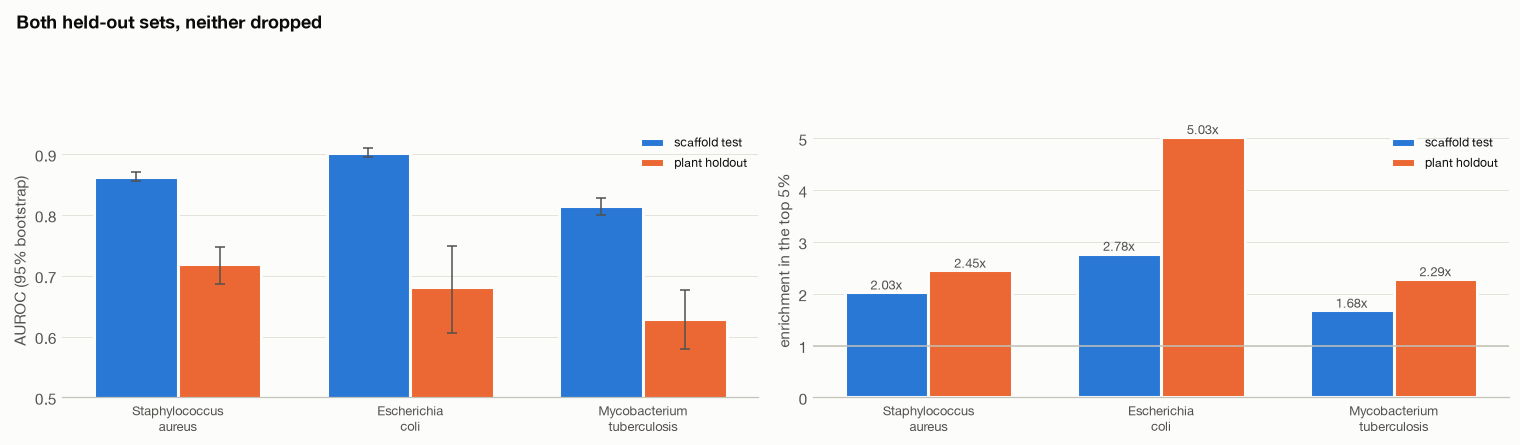

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
x = np.arange(len(CONFIG["pathogens"]))
width = 0.36
for i, name in enumerate(("scaffold test", "plant holdout")):
    block = [headline.loc[(o, name)] for o in CONFIG["pathogens"]]
    auroc = [b["AUROC"] for b in block]
    lo = [b["AUROC"] - b["AUROC lo"] for b in block]
    hi = [b["AUROC hi"] - b["AUROC"] for b in block]
    axes[0].bar(x + (i - 0.5) * width, auroc, width=width, yerr=[lo, hi], capsize=3,
                color=viz.SERIES[i], edgecolor=viz.SURFACE, linewidth=2,
                error_kw=dict(ecolor=viz.INK_SECONDARY, lw=1), label=name)
    enrich = [b["enrichment top 5%"] for b in block]
    axes[1].bar(x + (i - 0.5) * width, enrich, width=width, color=viz.SERIES[i],
                edgecolor=viz.SURFACE, linewidth=2, label=name)
    for xi, v in zip(x + (i - 0.5) * width, enrich):
        axes[1].text(xi, v, f"{v:.2f}x", ha="center", va="bottom", fontsize=8.5,
                     color=viz.INK_SECONDARY)
axes[0].set_ylim(0.5, 0.95)
axes[0].set_ylabel("AUROC (95% bootstrap)")
axes[1].axhline(1.0, color=viz.AXIS, linewidth=1)
axes[1].set_ylabel("enrichment in the top 5%")
for ax in axes:
    ax.set_xticks(x, [o.replace(" ", "\n") for o in CONFIG["pathogens"]], fontsize=8.5)
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8)
fig.suptitle("Both held-out sets, neither dropped", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "05_held_out")
plt.show()

## 2. Which number leads

**Settled: the plant holdout leads, the scaffold test set is reported beside it, and the
difference is named as a distance effect rather than two attempts at the same measurement.**
Both reviews reached that independently. This section keeps the argument, because a number that
leads without its reasoning is just a number.

**The case for the scaffold test set.** It is the evaluation the project settled on. It is
comparable with the bioactivity-prediction literature, which almost always reports a scaffold or
random split. It rests on thousands of compounds rather than hundreds, so its intervals are tight.

**The case for the plant holdout.** It is the only partition made of the chemistry the deliverable
is drawn from. 03 measured how far each held-out set sits from training: the scaffold test set has
a median nearest-neighbour Tanimoto around 0.67 to 0.70 with roughly a fifth of compounds above
0.80, while the plant holdout sits at 0.39 to 0.47. A scaffold split holds out scaffolds, not
analogues, so a congeneric series spreads across several scaffolds and lands on both sides. The
higher scaffold-test AUROC is therefore partly an analogue-proximity artefact, and the plant number
is what a wet lab should expect.

**Two further reasons the scaffold number should not lead**, both found in review and both
measured rather than argued. The deduplication key used to be tautomer-sensitive, so a molecule
stored as an enol in one database and a ketone in another counted as two compounds and could sit
on both sides of the split; that is fixed here and section 2a reports what it moved. And the
scaffold split never scores acyclic chemistry at all, because Bemis-Murcko gives every acyclic
molecule the same placeholder scaffold and the whole block lands in training. The plant holdout
contains that chemistry and is scored on it.

The cost of leading with the higher number is that the first serious reader finds the gap
themselves. It was found twice during review of this repository alone.

In [4]:
gap = pd.DataFrame({
    "scaffold test AUROC": [headline.loc[(o, "scaffold test"), "AUROC"] for o in CONFIG["pathogens"]],
    "plant holdout AUROC": [headline.loc[(o, "plant holdout"), "AUROC"] for o in CONFIG["pathogens"]],
}, index=CONFIG["pathogens"])
gap["difference"] = gap["scaffold test AUROC"] - gap["plant holdout AUROC"]
gap["intervals overlap"] = [
    not (headline.loc[(o, "plant holdout"), "AUROC hi"]
         < headline.loc[(o, "scaffold test"), "AUROC lo"])
    for o in CONFIG["pathogens"]
]
gap.rename_axis("pathogen").style.format("{:.3f}", subset=gap.columns[:3])

,scaffold test AUROC,plant holdout AUROC,difference,intervals overlap
pathogen,,,,
Staphylococcus aureus,0.863,0.719,0.144,False
Escherichia coli,0.903,0.682,0.221,False
Mycobacterium tuberculosis,0.815,0.629,0.186,False


## 3. What the model is reading

Feature importance for the biological reading the team asked for, by **permutation** rather than by
impurity. Impurity importance systematically inflates continuous features against binary ones, and
comparing a block of 14 continuous descriptors with 2,048 binary bits is exactly the case where
that bias decides the answer. Permutation importance asks a question that is fair to both: shuffle
these columns, how much AUROC is lost.

Two scales are measured. The whole descriptor block against the whole fingerprint block, which
says where the signal lives, and then each descriptor on its own, which is the part a chemist can
read.

**Measured on the plant holdout, not on validation.** Importance on near chemistry tells you what
the model uses to separate compounds it has near-twins for, which is not the question. What
matters is what it uses on the chemistry it will actually be asked about.

**What would be bad news.** If molecular weight or logP dominates, the model is plausibly reading
how drug-like and well studied a molecule is rather than whether it kills bacteria, because large
lipophilic compounds are both more likely to be tested and more likely to be reported active.
That would be an assay and curation artefact wearing the clothes of a result, and it is reported
here whether or not it is flattering.

In [5]:
def permutation_drop(model, X, y, columns, repeats=5, seed=0):
    rng = np.random.default_rng(seed)
    base = models.roc_auc_score(y, model.predict_proba(X)[:, 1])
    drops = []
    for _ in range(repeats):
        shuffled = X.copy()
        order = rng.permutation(len(shuffled))
        shuffled[:, columns] = shuffled[order][:, columns]
        drops.append(base - models.roc_auc_score(y, model.predict_proba(shuffled)[:, 1]))
    return float(np.mean(drops)), float(np.std(drops))


block_rows, named_rows = [], []
n_desc = len(featureset.DESCRIPTOR_NAMES)
for organism in CONFIG["pathogens"]:
    payload = fitted[organism]
    feature_name = payload["feature_set"]
    slug = curation.slug(organism)
    bundle = featureset.load(f"03_features_{slug}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    scored_on = np.where(frame.partition.eq(IMPORTANCE_PARTITION).to_numpy())[0]
    X = featureset.matrix(bundle, feature_name)[scored_on]
    y = bundle["label"][scored_on]

    if feature_name == "hybrid":
        bits = np.arange(X.shape[1] - n_desc)
        descs = np.arange(X.shape[1] - n_desc, X.shape[1])
    elif feature_name == "descriptors":
        bits, descs = np.array([], dtype=int), np.arange(X.shape[1])
    else:
        bits, descs = np.arange(X.shape[1]), np.array([], dtype=int)

    row = {"pathogen": organism, "feature set": feature_name}
    for label, columns in [("fingerprint bits", bits), ("physicochemical block", descs)]:
        if len(columns):
            mean, sd = permutation_drop(payload["model_object"], X, y, columns,
                                        seed=CONFIG["seed"])
            row[f"AUROC lost, {label}"] = mean
            row[f"sd, {label}"] = sd
        else:
            row[f"AUROC lost, {label}"] = np.nan
            row[f"sd, {label}"] = np.nan
    block_rows.append(row)

    if len(descs):
        for offset, name in enumerate(featureset.DESCRIPTOR_NAMES):
            mean, _ = permutation_drop(payload["model_object"], X, y,
                                       np.array([descs[offset]]), repeats=3,
                                       seed=CONFIG["seed"])
            named_rows.append({"pathogen": organism, "descriptor": name, "AUROC lost": mean})
    del bundle, X
    print(f"  {organism}: permutation importance done", flush=True)

blocks = pd.DataFrame(block_rows).set_index("pathogen")
display(blocks.style.format("{:.4f}", subset=[c for c in blocks.columns if c != "feature set"]))

  Staphylococcus aureus: permutation importance done


  Escherichia coli: permutation importance done


  Mycobacterium tuberculosis: permutation importance done


,feature set,"AUROC lost, fingerprint bits","sd, fingerprint bits","AUROC lost, physicochemical block","sd, physicochemical block"
pathogen,,,,,
Staphylococcus aureus,hybrid,0.1393,0.0069,0.1485,0.0110
Escherichia coli,hybrid,0.1158,0.0173,0.1052,0.0262
Mycobacterium tuberculosis,morgan,0.1443,0.0215,nan,nan


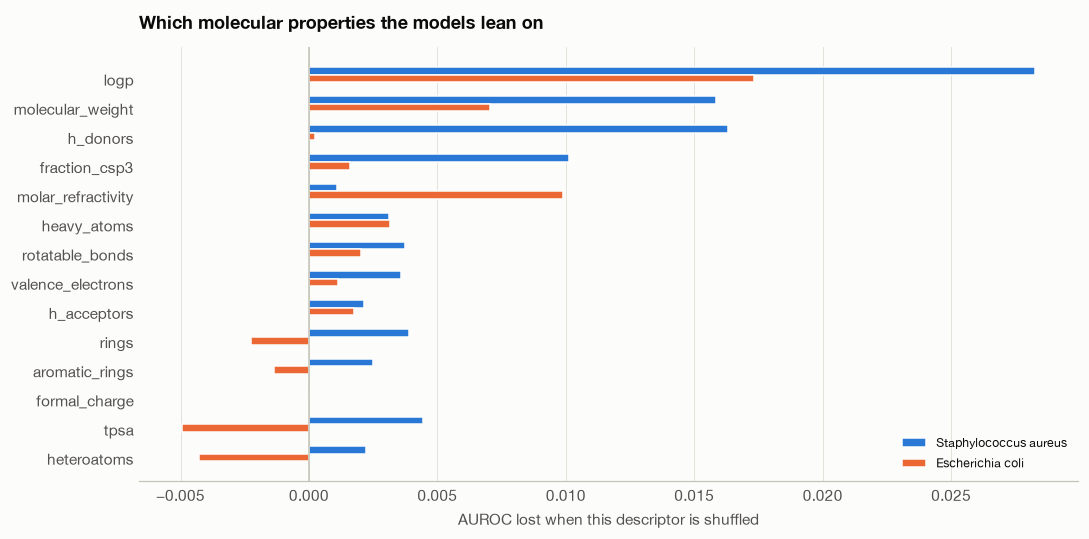

pathogen,Escherichia coli,Staphylococcus aureus
descriptor,,
logp,0.0173,0.0283
molecular_weight,0.0070,0.0158
h_donors,0.0002,0.0163
fraction_csp3,0.0016,0.0101
molar_refractivity,0.0099,0.0011
heavy_atoms,0.0032,0.0031
rotatable_bonds,0.0020,0.0037
valence_electrons,0.0011,0.0036
h_acceptors,0.0018,0.0022


In [6]:
named = pd.DataFrame(named_rows)
if len(named):
    pivot = named.pivot(index="descriptor", columns="pathogen", values="AUROC lost")
    pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(10, 5))
    y_pos = np.arange(len(pivot))
    width = 0.26
    for i, organism in enumerate(CONFIG["pathogens"]):
        if organism in pivot.columns:
            ax.barh(y_pos + (i - 1) * width, pivot[organism], height=width,
                    color=viz.SERIES[i], edgecolor=viz.SURFACE, linewidth=1, label=organism)
    ax.set_yticks(y_pos, pivot.index)
    ax.invert_yaxis()
    ax.axvline(0, color=viz.AXIS, linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("AUROC lost when this descriptor is shuffled")
    ax.legend(fontsize=8)
    ax.set_title("Which molecular properties the models lean on")
    viz.save(fig, "05_feature_importance")
    plt.show()
    display(pivot.round(4))
else:
    print("No model uses the descriptor block, so there is no named ranking to show.")

### 3b. Does the model beat sorting the file by one number

The sharpest test of whether a model has earned its complexity is to compare it with the dumbest
thing that could work. Here that is ranking the plant holdout by a single physicochemical
descriptor, with no training and no model at all.

This is the check most likely to embarrass the project, which is exactly why it is run and
reported rather than left for someone else to run.

**The descriptor and its sign are chosen on the training partition**, then scored once on the
plant holdout. Choosing either on the holdout, which is the obvious way to write this and the way
we wrote it first, fits the baseline to the evaluation set: it silently picks whichever of
fourteen descriptors and whichever of two signs happens to work there. That inflates the baseline
and therefore flatters any model compared against it, and we only caught it because the comparison
was re-derived independently.

In [7]:
ladder_rows, paired_rows = [], []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    payload = fitted[organism]
    params, deliverable_set = payload["params"], payload["feature_set"]
    bundle = featureset.load(f"03_features_{slug}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    part = {n: np.where(frame.partition.eq(n).to_numpy())[0] for n in ("train", "test", "plant")}
    y = bundle["label"]

    # Choose BOTH the descriptor and its sign on the training partition. Picking either on the
    # holdout fits the evaluation set and inflates the baseline, which makes the model look
    # better than it is by comparison.
    best = None
    for column, name in enumerate(featureset.DESCRIPTOR_NAMES):
        train_values = bundle["descriptors"][part["train"], column].astype(float)
        for direction in (1, -1):
            train_auroc = models.roc_auc_score(y[part["train"]], direction * train_values)
            if best is None or train_auroc > best[1]:
                best = (name, train_auroc, direction, column)
    descriptor_name, _, direction, column = best
    plant_values = bundle["descriptors"][part["plant"], column].astype(float)
    best_plant = models.roc_auc_score(y[part["plant"]], direction * plant_values)
    best = (descriptor_name, best_plant, direction)

    wanted = sorted({"descriptors", deliverable_set})
    matrices = featureset.matrices(bundle, wanted)
    scores = {}
    for name, X in matrices.items():
        model = models.random_forest(seed=CONFIG["seed"], **params).fit(
            X[part["train"]], y[part["train"]])
        for setname in ("test", "plant"):
            scores[(name, setname)] = model.predict_proba(X[part[setname]])[:, 1]

    ladder_rows.append({
        "pathogen": organism,
        "deliverable feature set": deliverable_set,
        "best single descriptor": f"{best[0]} ({'higher' if best[2] > 0 else 'lower'} = active)",
        "1 descriptor, no model": best[1],
        "14 descriptors, tuned model": models.roc_auc_score(
            y[part["plant"]], scores[("descriptors", "plant")]),
        "deliverable model": models.roc_auc_score(
            y[part["plant"]], scores[(deliverable_set, "plant")]),
    })

    if deliverable_set != "descriptors":
        for setname in ("test", "plant"):
            truth = y[part[setname]]
            rng = np.random.default_rng(CONFIG["seed"])
            diffs = []
            for _ in range(400):
                index = rng.integers(0, len(truth), len(truth))
                if len(np.unique(truth[index])) < 2:
                    continue
                diffs.append(
                    models.roc_auc_score(truth[index], scores[(deliverable_set, setname)][index])
                    - models.roc_auc_score(truth[index], scores[("descriptors", setname)][index]))
            paired_rows.append({
                "pathogen": organism,
                "set": "scaffold test" if setname == "test" else "plant holdout",
                "structure adds": float(np.mean(diffs)),
                "95% lo": float(np.percentile(diffs, 2.5)),
                "95% hi": float(np.percentile(diffs, 97.5)),
                "excludes zero": bool(np.percentile(diffs, 2.5) > 0),
            })
    del bundle, matrices

ladder = pd.DataFrame(ladder_rows).set_index("pathogen")
display(ladder.style.format({c: "{:.4f}" for c in (
    "1 descriptor, no model", "14 descriptors, tuned model", "deliverable model")}))
display(pd.DataFrame(paired_rows).set_index(["pathogen", "set"]).style.format(
    {c: "{:.4f}" for c in ("structure adds", "95% lo", "95% hi")}))

,deliverable feature set,best single descriptor,"1 descriptor, no model","14 descriptors, tuned model",deliverable model
pathogen,,,,,
Staphylococcus aureus,hybrid,molecular_weight (higher = active),0.6187,0.6906,0.7189
Escherichia coli,hybrid,heteroatoms (higher = active),0.6696,0.6502,0.6816
Mycobacterium tuberculosis,morgan,molecular_weight (higher = active),0.6434,0.6590,0.6289


**The first table is a ladder, and the rungs matter separately.** One descriptor with no model at
all, then all fourteen descriptors through the tuned model, then the deliverable. Everything is
fitted with the tuned hyperparameters so the baseline rows and the headline row come from the same
configuration rather than from a convenient one.

Reading it rung by rung separates two explanations that are easy to confuse. If the fourteen-feature
block beats its own best single member, physicochemical properties are carrying *joint*
transferable signal, and structure adding more on top means the model has earned its complexity. If
the block does **not** beat its best single member, the honest description is far blunter: the model
is reading one property, and the other thirteen features and the 2,048 structural bits are not
contributing anything measurable on the chemistry we will deploy on.

Expect this answer to differ by pathogen, and say so per pathogen rather than writing one sentence
over all three. A judge asking "so which is it" deserves three answers if there are three.

**The second table is the mechanism.** On the scaffold test set structural features add a large and
unambiguous amount over the descriptor block. On the plant holdout that advantage shrinks, and
where its interval includes zero, structure has stopped transferring altogether. That is the
distance effect appearing in the feature dimension rather than the score dimension: the part of the
model that does the work on near chemistry is precisely the part that does not travel. "The far set
is harder" was the right observation and the wrong explanation.

**A check that this is chemistry and not noise.** If the best descriptor is lipophilicity, compare
its direction across pathogens. A flip between a Gram-positive and a Gram-negative organism is the
textbook permeability difference: the Gram-negative outer membrane favours smaller, more polar
compounds. A model recovering a known trend is doing something real. It is doing something real
about bulk properties, which is a weaker claim than structure-specific prediction and is the claim
we should make.

### 3a. SHAP attribution

Permutation importance above says how much each block is worth to the model overall. SHAP says how
each feature moved each individual prediction, which is what lets a chemist ask why *this*
compound scored as it did rather than only which properties matter on average.

Computed on the **uncalibrated** model, because Platt scaling is a monotonic reparameterisation
and attributing through it would mix the model's reasoning with the calibration curve. The tree
explainer is exact for a random forest rather than sampled, so no approximation error is being
hidden. A subsample of the validation partition keeps it to a sensible runtime.

In [8]:
import shap

SHAP_SAMPLE = int(os.environ.get("ETHNOHACK_SHAP_SAMPLE", 300))

shap_named, shap_blocks = [], []
n_desc = len(featureset.DESCRIPTOR_NAMES)
for organism in CONFIG["pathogens"]:
    payload = fitted[organism]
    feature_name = payload["feature_set"]
    slug = curation.slug(organism)
    bundle = featureset.load(f"03_features_{slug}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    validation = np.where(frame.partition.eq("validation").to_numpy())[0]
    rng = np.random.default_rng(CONFIG["seed"])
    probe = rng.choice(validation, min(SHAP_SAMPLE, len(validation)), replace=False)
    X = featureset.matrix(bundle, feature_name)[probe]

    explainer = shap.TreeExplainer(payload["model_object"])
    values = explainer.shap_values(X, check_additivity=False)
    if isinstance(values, list):
        values = values[1]
    elif values.ndim == 3:
        values = values[:, :, 1]
    magnitude = np.abs(values).mean(axis=0)

    if feature_name == "hybrid":
        shap_blocks.append({"pathogen": organism, "feature set": feature_name,
                            "mean |SHAP|, fingerprint bits": float(magnitude[:-n_desc].sum()),
                            "mean |SHAP|, physicochemical": float(magnitude[-n_desc:].sum())})
        for name, value in zip(featureset.DESCRIPTOR_NAMES, magnitude[-n_desc:]):
            shap_named.append({"pathogen": organism, "descriptor": name,
                               "mean |SHAP|": float(value)})
    elif feature_name == "descriptors":
        shap_blocks.append({"pathogen": organism, "feature set": feature_name,
                            "mean |SHAP|, fingerprint bits": 0.0,
                            "mean |SHAP|, physicochemical": float(magnitude.sum())})
        for name, value in zip(featureset.DESCRIPTOR_NAMES, magnitude):
            shap_named.append({"pathogen": organism, "descriptor": name,
                               "mean |SHAP|": float(value)})
    else:
        shap_blocks.append({"pathogen": organism, "feature set": feature_name,
                            "mean |SHAP|, fingerprint bits": float(magnitude.sum()),
                            "mean |SHAP|, physicochemical": 0.0})
    print(f"  {organism}: SHAP on {len(probe)} validation compounds", flush=True)
    del bundle, X
display(pd.DataFrame(shap_blocks).set_index("pathogen").style.format(
    {c: "{:.4f}" for c in ("mean |SHAP|, fingerprint bits", "mean |SHAP|, physicochemical")}))

  Staphylococcus aureus: SHAP on 300 validation compounds


  Escherichia coli: SHAP on 300 validation compounds


  Mycobacterium tuberculosis: SHAP on 300 validation compounds


,feature set,"mean |SHAP|, fingerprint bits","mean |SHAP|, physicochemical"
pathogen,,,
Staphylococcus aureus,hybrid,566310942787513483264.0000,18256247787481387008.0000
Escherichia coli,hybrid,9247286517027852.0000,1248810250611013.0000
Mycobacterium tuberculosis,morgan,138482110131880424510586880.0000,0.0000


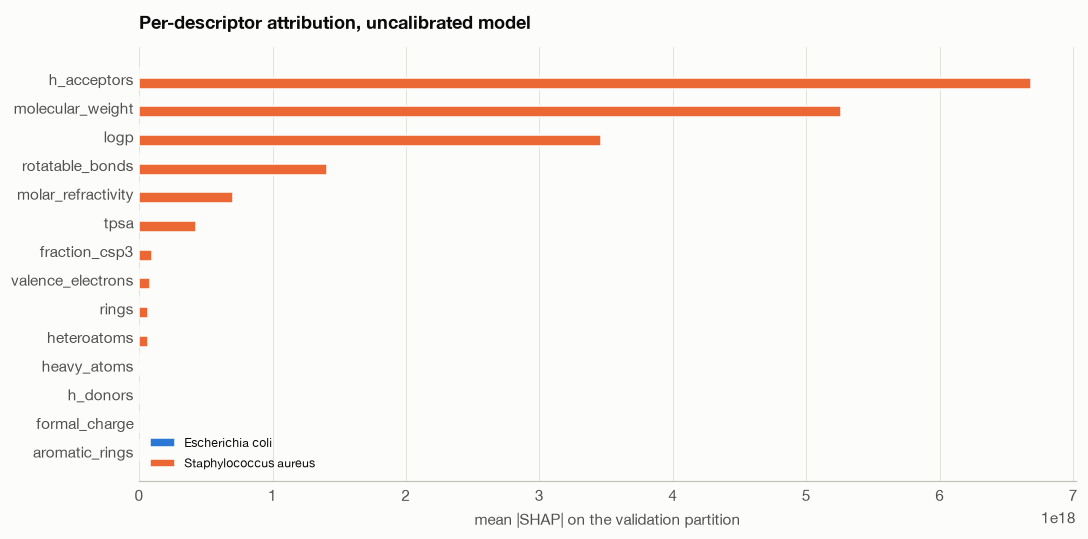

pathogen,Escherichia coli,Staphylococcus aureus
descriptor,,
h_acceptors,8.040833e+13,6.685492e+18
molecular_weight,1.520654e+14,5.258360e+18
logp,6.788870e+13,3.460779e+18
rotatable_bonds,6.946903e+11,1.408516e+18
molar_refractivity,1.517517e+14,7.041631e+17
tpsa,1.544012e+14,4.236268e+17
fraction_csp3,1.438757e+14,9.412285e+16
valence_electrons,3.432248e+13,7.878630e+16
rings,1.349781e+12,6.901862e+16


In [9]:
named_shap = pd.DataFrame(shap_named)
if len(named_shap):
    pivot = named_shap.pivot(index="descriptor", columns="pathogen", values="mean |SHAP|")
    pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(10, 5))
    y_pos = np.arange(len(pivot))
    width = 0.38
    for i, organism in enumerate(pivot.columns):
        ax.barh(y_pos + (i - 0.5) * width, pivot[organism], height=width,
                color=viz.SERIES[i], edgecolor=viz.SURFACE, linewidth=1, label=organism)
    ax.set_yticks(y_pos, pivot.index)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("mean |SHAP| on the validation partition")
    ax.legend(fontsize=8)
    ax.set_title("Per-descriptor attribution, uncalibrated model")
    viz.save(fig, "05_shap")
    plt.show()
    display(pivot.round(4))
else:
    print("No model in this run uses the descriptor block, so there is no named SHAP ranking.")

## 4. The screening set

Every plant compound LOTUS reports that has no measured antibacterial activity in our tables. The
count here is **compounds**, deduplicated by InChIKey skeleton the way every other stage of this
pipeline is. The raw structure count is larger because stereoisomers and salt forms each get their
own row, and ranking those separately would put the same molecule on the shortlist several times.

In [10]:
plant = pd.read_parquet(data.PROCESSED / "01_plant_structures.parquet")
plant["skeleton"] = plant.structure_inchikey.str.split("-").str[0]

labelled = set()
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    labelled |= set(pd.read_parquet(
        data.PROCESSED / f"02_labelled_{slug}.parquet", columns=["skeleton"]
    ).skeleton)

plant["smiles_length"] = plant.structure_smiles.str.len()
candidates = (
    plant.sort_values(["skeleton", "smiles_length", "structure_smiles"])
    .drop_duplicates("skeleton")
    .loc[lambda d: ~d.skeleton.isin(labelled)]
    .reset_index(drop=True)
)
pd.Series({
    "reported structures in LOTUS (plants)": len(plant),
    "distinct compounds (InChIKey skeleton)": plant.skeleton.nunique(),
    "already measured against one of our three pathogens": len(labelled & set(plant.skeleton)),
    "screening set, never measured": len(candidates),
    "with an NPClassifier pathway": int(candidates.np_pathway.notna().sum()),
}, name="value").to_frame()

,value
reported structures in LOTUS (plants),153745
distinct compounds (InChIKey skeleton),99556
already measured against one of our three pathogens,1847
"screening set, never measured",97709
with an NPClassifier pathway,94598


In [11]:
start = time.time()
screen_table = candidates.rename(columns={"structure_smiles": "canonical_smiles"})
screen_table = screen_table[["skeleton", "canonical_smiles", "np_pathway",
                             "np_superclass", "np_class"]]
NO_LABEL = -1
screen_table["label"] = NO_LABEL
screen_table["from_plant"] = True
screen_table["family"] = np.nan
screen_bundle = featureset.build(screen_table)
print(f"featurised {len(screen_bundle['skeleton']):,} candidates in {time.time() - start:.0f}s")
assert set(np.unique(screen_bundle["label"])) == {NO_LABEL}, (
    "the screening set must carry no real labels: these compounds have never been measured, "
    "and any metric computed against them would be meaningless"
)

annotation = screen_table.set_index("skeleton")
keep = pd.Index(screen_bundle["skeleton"])
screen_meta = annotation.loc[keep, ["canonical_smiles", "np_pathway", "np_superclass", "np_class"]]
pathways = screen_meta.np_pathway.fillna("(not classified)").value_counts(normalize=True)
pathways.head(8).mul(100).round(1).rename("share of screening set (%)").to_frame()

    featurised 20,000/97,709


    featurised 40,000/97,709


    featurised 60,000/97,709


    featurised 80,000/97,709


featurised 97,709 candidates in 50s


,share of screening set (%)
np_pathway,
Terpenoids,45.8
Shikimates and Phenylpropanoids,25.5
Alkaloids,10.4
Polyketides,5.3
Fatty acids,4.8
(not classified),3.2
Alkaloids $ Terpenoids,1.8
Amino acids and Peptides,1.1


## 5. Scoring, applicability domain and the shortlist

Three steps per pathogen. Score everything, keep the top `candidate_pool`, then choose
`shortlist_size` from that pool by farthest-point sampling so the compounds that go to a chemist
are not fifty variations on one skeleton.

**Ranking uses the raw model score; the calibrated probability is what gets displayed.** Isotonic
regression is a step function and collapses the whole screening set onto a few dozen levels, so
ranking on it would cut the top 500 out of one flat tier by row order rather than by the model.
Isotonic is monotone, so the two orderings agree wherever the raw scores differ. The printed line
below shows how many distinct values each carries, which is the size of the problem being avoided.

The applicability domain travels with every candidate. These compounds were never tested, so they
sit further from the training chemistry than even the plant holdout did, and a confident score on a
compound unlike anything the model has seen is the least trustworthy output this pipeline can
produce.

In [12]:
DOMAIN_CUTOFF = None


def nearest_tanimoto(query, reference, chunk=3000):
    best = np.zeros(len(query))
    for start in range(0, len(reference), chunk):
        block = reference[start:start + chunk]
        inter = query @ block.T
        union = query.sum(1)[:, None] + block.sum(1)[None, :] - inter
        best = np.maximum(best, (inter / np.maximum(union, 1)).max(axis=1))
    return best


def farthest_point(matrix, count, seed=0):
    chosen = [int(np.random.default_rng(seed).integers(len(matrix)))]
    inter = matrix @ matrix[chosen[0]]
    union = matrix.sum(1) + matrix[chosen[0]].sum() - inter
    nearest = inter / np.maximum(union, 1)
    while len(chosen) < min(count, len(matrix)):
        pick = int(np.argmin(nearest))
        chosen.append(pick)
        inter = matrix @ matrix[pick]
        union = matrix.sum(1) + matrix[pick].sum() - inter
        nearest = np.maximum(nearest, inter / np.maximum(union, 1))
    return chosen


screen_morgan = featureset.unpack_morgan(screen_bundle["morgan"])
needed = sorted({fitted[o]["feature_set"] for o in CONFIG["pathogens"]})
screen_matrices = featureset.matrices(screen_bundle, needed)
print(f"built {needed} for {len(screen_bundle['skeleton']):,} candidates")

occurrences = pd.read_parquet(
    data.PROCESSED / "01_plant_occurrences.parquet",
    columns=["structure_smiles", "organism_name", "family", "reference_doi"],
).dropna(subset=["structure_smiles"])
occurrences["skeleton"] = occurrences.structure_smiles.map(
    data.canonical_skeleton_map(list(occurrences.structure_smiles.unique()), show_progress=False)
)
grouped = occurrences.dropna(subset=["skeleton"]).groupby("skeleton")
provenance = pd.DataFrame({
    "source_plants": grouped.organism_name.apply(
        lambda v: "; ".join(sorted(set(v.dropna()))[:4])),
    "n_source_plants": grouped.organism_name.nunique(),
    "plant_families": grouped.family.apply(lambda v: "; ".join(sorted(set(v.dropna()))[:3])),
    "reference_doi": grouped.reference_doi.apply(
        lambda v: next(iter(sorted(set(v.dropna()))), None)),
}).reset_index()
print(f"provenance for {len(provenance):,} plant compounds")

plant_distances = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    bundle = featureset.load(f"03_features_{slug}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    morgan = featureset.unpack_morgan(bundle["morgan"])
    train_i = np.where(frame.partition.eq("train").to_numpy())[0]
    plant_i = np.where(frame.partition.eq("plant").to_numpy())[0]
    plant_distances.append(nearest_tanimoto(morgan[plant_i], morgan[train_i]))
    del morgan, bundle
plant_distances = np.concatenate(plant_distances)
DOMAIN_CUTOFF = float(np.percentile(plant_distances, CONFIG["domain_cutoff_percentile"]))
print(f"plant holdout nearest-neighbour Tanimoto: median {np.median(plant_distances):.3f}, "
      f"10th pct {np.percentile(plant_distances, 10):.3f}")
print(f"applicability-domain cutoff set to the {CONFIG['domain_cutoff_percentile']}th percentile "
      f"of that distribution: {DOMAIN_CUTOFF:.3f}")

shortlists, domain_rows, screen_scores = {}, [], {}
rng = np.random.default_rng(CONFIG["seed"])
for organism in CONFIG["pathogens"]:
    payload = fitted[organism]
    feature_name = payload["feature_set"]
    X = screen_matrices[feature_name]
    scores = payload["model_object"].predict_proba(X)[:, 1]
    displayed = payload["calibrator"].predict_proba(X)[:, 1]
    screen_scores[organism] = scores

    train_bundle = featureset.load(f"03_features_{curation.slug(organism)}")
    train_frame = pd.read_parquet(
        data.PROCESSED / f"03_splits_{curation.slug(organism)}.parquet"
    )
    train_index = np.where(train_frame.partition.eq("train").to_numpy())[0]
    train_morgan = featureset.unpack_morgan(train_bundle["morgan"])[train_index]
    del train_bundle

    probe = rng.choice(len(screen_morgan), CONFIG["domain_sample"], replace=False)
    sampled_distance = nearest_tanimoto(screen_morgan[probe], train_morgan)
    domain_rows.append({
        "pathogen": organism,
        "median nearest Tanimoto (screening set)": float(np.median(sampled_distance)),
        "share in domain": float((sampled_distance >= DOMAIN_CUTOFF).mean()),
    })

    top = np.argsort(-scores)[: CONFIG["candidate_pool"]]
    top_distance = nearest_tanimoto(screen_morgan[top], train_morgan)

    in_domain = np.where(top_distance >= DOMAIN_CUTOFF)[0]
    out_domain = np.where(top_distance < DOMAIN_CUTOFF)[0]
    pick_in = farthest_point(screen_morgan[top[in_domain]], CONFIG["shortlist_size"],
                             CONFIG["seed"]) if len(in_domain) else []
    pick_out = farthest_point(screen_morgan[top[out_domain]], CONFIG["exploratory_size"],
                              CONFIG["seed"]) if len(out_domain) else []
    picked = np.concatenate([in_domain[pick_in], out_domain[pick_out]]).astype(int)
    chosen = top[picked]
    print(f"  {organism}: pool {len(top)} = {len(in_domain)} in domain + {len(out_domain)} "
          f"exploratory; taking {len(pick_in)} + {len(pick_out)}", flush=True)

    frame = pd.DataFrame({
        "selection_order": np.arange(1, len(chosen) + 1),
        "skeleton": screen_bundle["skeleton"][chosen],
        "canonical_smiles": screen_meta.canonical_smiles.to_numpy()[chosen],
        "predicted_probability": displayed[chosen],
        "ranking_score": scores[chosen],
        "nearest_training_tanimoto": top_distance[picked],
        "in_applicability_domain": top_distance[picked] >= DOMAIN_CUTOFF,
        "fingerprint_twin_of_training": top_distance[picked] >= 0.99,
        "np_pathway": screen_meta.np_pathway.to_numpy()[chosen],
        "np_superclass": screen_meta.np_superclass.to_numpy()[chosen],
    })
    frame = frame.merge(provenance, on="skeleton", how="left")
    frame = frame.sort_values("ranking_score", ascending=False).reset_index(drop=True)
    frame.insert(0, "rank", np.arange(1, len(frame) + 1))
    assert frame.ranking_score.is_monotonic_decreasing, "rank must follow the ranking score"
    frame["tier"] = np.where(frame.in_applicability_domain, "in-domain", "exploratory")
    shortlists[organism] = frame
    print(f"{organism}: scored {len(scores):,} "
          f"({len(np.unique(scores)):,} distinct raw vs {len(np.unique(displayed)):,} calibrated), "
          f"pool {len(top)}, shortlist {len(chosen)}", flush=True)
    del train_morgan
domain = pd.DataFrame(domain_rows).set_index("pathogen")
domain.style.format({"median nearest Tanimoto (screening set)": "{:.3f}",
                     "share in domain": "{:.1%}"})

built ['hybrid', 'morgan'] for 97,709 candidates


provenance for 99,037 plant compounds


plant holdout nearest-neighbour Tanimoto: median 0.435, 10th pct 0.272
applicability-domain cutoff set to the 25th percentile of that distribution: 0.328


  Staphylococcus aureus: pool 500 = 375 in domain + 125 exploratory; taking 50 + 15


Staphylococcus aureus: scored 97,709 (3,314 distinct raw vs 3,281 calibrated), pool 500, shortlist 65


  Escherichia coli: pool 500 = 144 in domain + 356 exploratory; taking 50 + 15


Escherichia coli: scored 97,709 (2,970 distinct raw vs 2,933 calibrated), pool 500, shortlist 65


  Mycobacterium tuberculosis: pool 500 = 166 in domain + 334 exploratory; taking 50 + 15


Mycobacterium tuberculosis: scored 97,709 (94,353 distinct raw vs 94,353 calibrated), pool 500, shortlist 65


,median nearest Tanimoto (screening set),share in domain
pathogen,,
Staphylococcus aureus,0.352,58.5%
Escherichia coli,0.333,52.4%
Mycobacterium tuberculosis,0.294,34.9%


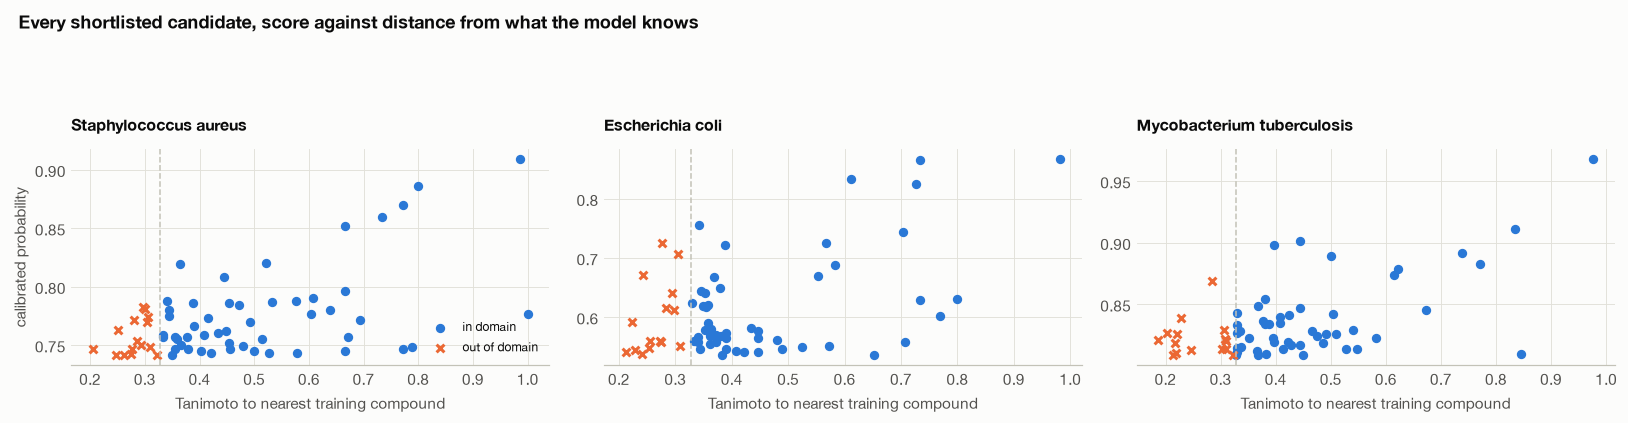

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    frame = shortlists[organism]
    inside = frame[frame.in_applicability_domain]
    outside = frame[~frame.in_applicability_domain]
    ax.scatter(inside.nearest_training_tanimoto, inside.predicted_probability,
               s=26, color=viz.SERIES[0], label="in domain")
    ax.scatter(outside.nearest_training_tanimoto, outside.predicted_probability,
               s=26, color=viz.SERIES[1], marker="x", label="out of domain")
    ax.axvline(DOMAIN_CUTOFF, color=viz.AXIS, linewidth=1, linestyle="--")
    ax.set_xlabel("Tanimoto to nearest training compound")
    ax.set_title(organism, fontsize=10.5)
axes[0].set_ylabel("calibrated probability")
axes[0].legend(fontsize=8)
fig.suptitle("Every shortlisted candidate, score against distance from what the model knows",
             x=0.02, ha="left", fontweight="bold")
viz.save(fig, "05_applicability_domain")
plt.show()

### Candidates the model has effectively already seen

A candidate can be absent from every label table and still be indistinguishable from a training
compound, because two different molecules can share a Morgan fingerprint. The flag below counts
them, and they are worth looking at rather than quietly dropping.

In [14]:
twins = []
for organism in CONFIG["pathogens"]:
    frame = shortlists[organism]
    twins.append({
        "pathogen": organism,
        "shortlisted": len(frame),
        "fingerprint-identical to a training compound": int(frame.fingerprint_twin_of_training.sum()),
        "median distance to training": float(frame.nearest_training_tanimoto.median()),
    })
display(pd.DataFrame(twins).set_index("pathogen").style.format(
    {"median distance to training": "{:.3f}"}))

example = None
for organism in CONFIG["pathogens"]:
    hit = shortlists[organism][shortlists[organism].fingerprint_twin_of_training]
    if len(hit):
        example = (organism, hit.iloc[0])
        break
if example is not None:
    organism, row = example
    print(f"Example, {organism}: {row.skeleton}")
    print(f"  {row.canonical_smiles}")
    print(f"  ranked {int(row['rank'])}, raw score {row.ranking_score:.3f}, "
          f"Tanimoto to nearest training compound {row.nearest_training_tanimoto:.3f}")

,shortlisted,fingerprint-identical to a training compound,median distance to training
pathogen,,,
Staphylococcus aureus,65,1,0.415
Escherichia coli,65,0,0.368
Mycobacterium tuberculosis,65,0,0.387


Example, Staphylococcus aureus: QVOQAFZRUJLJRH
  CCCCCCCCC[N+]12CC[N+](CC1)(CC2)CCCCCCCCC
  ranked 22, raw score 0.693, Tanimoto to nearest training compound 1.000


These are real molecules absent from every label table, so the pipeline has not leaked. What they
show is a limit of the representation. A Morgan fingerprint at radius 2 records the substructure
environments present, not how many times a repeating one occurs, so a C9 alkyl chain and a C12
alkyl chain produce the same bits. The example above is a bis-quaternary ammonium surfactant whose
nearest training neighbours are longer-chain homologs of the same series, all labelled active.

Two consequences, and both belong in front of a chemist rather than buried. The model cannot
distinguish chain-length homologs at all, so a candidate flagged here is a recall of a known
active rather than a new idea. And the series it recalls is a quaternary ammonium surfactant,
which kills bacteria by disrupting membranes, works on almost anything, and is exactly the kind of
promiscuous hit a screening campaign is supposed to discard. That the model ranks them highly is
expected, and it is a reason to read the shortlist with a chemist rather than to act on the rank
order alone.

### Is the shortlist a greasiness sort

Where **higher** logP goes with activity, there is an uncomfortable corollary worth measuring
rather than worrying about: lipophilic compounds that kill bacteria in a plate are the classic
in-vitro false positive. The direction table below decides which pathogens this applies to, and
it is not all of them: where lower logP goes with activity the concern does not arise.

It matters most for *M. tuberculosis*, whose lipid-rich cell wall makes a lipophilicity
association mechanistically expected rather than suspicious. That is exactly why it needs
flagging: the expected trend and the detergent artefact look identical in this data, so a chemist
has to tell them apart, and the pipeline cannot. Detergents and aggregators
disrupt membranes indiscriminately, look excellent in a well, and are worthless as drugs. The
quaternary ammonium surfactants already flagged in this notebook are the same phenomenon arriving
by a different route.

So this compares the logP distribution of each shortlist against the screening set it was drawn
from, counts how many shortlisted compounds sit above a plausible promiscuity cut-off, and
cross-tabs that against a structural surfactant flag. **Nothing is filtered on logP.** Flagging is
defensible; quietly dropping compounds for being inconvenient is not.

In [15]:
from rdkit import Chem
from rdkit.Chem import Crippen, Descriptors

PROMISCUITY_LOGP = 5.0


def surfactant_like(smiles):
    mol = Chem.MolFromSmiles(smiles) if smiles else None
    if mol is None:
        return False
    quaternary = any(a.GetSymbol() == "N" and a.GetFormalCharge() > 0 and a.GetDegree() == 4
                     for a in mol.GetAtoms())
    long_chain = mol.HasSubstructMatch(Chem.MolFromSmarts("[CH2]" + "[CH2]" * 7))
    return bool(quaternary or long_chain)


screen_logp = []
for smiles in pd.Series(screen_meta.canonical_smiles.to_numpy()).dropna().sample(
        min(5000, len(screen_meta)), random_state=CONFIG["seed"]):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        screen_logp.append(Crippen.MolLogP(mol))
screen_logp = np.array(screen_logp)

promiscuity_rows = []
shortlist_logp = {}
for organism in CONFIG["pathogens"]:
    frame = shortlists[organism]
    for tier in ("in-domain", "exploratory"):
        part = frame[frame.tier.eq(tier)]
        if not len(part):
            continue
        values, flags = [], []
        for smiles in part.canonical_smiles:
            mol = Chem.MolFromSmiles(smiles)
            values.append(Crippen.MolLogP(mol) if mol is not None else np.nan)
            flags.append(surfactant_like(smiles))
        values = np.array(values, dtype=float)
        if tier == "in-domain":
            shortlist_logp[organism] = values
        promiscuity_rows.append({
            "pathogen": organism,
            "tier": tier,
            "n": len(part),
            "median logP": float(np.nanmedian(values)),
            "screening-set median logP": float(np.median(screen_logp)),
            f"above logP {PROMISCUITY_LOGP:g}": int(np.nansum(values > PROMISCUITY_LOGP)),
            "surfactant-like": int(np.sum(flags)),
            "percentile in screening set": float(
                (screen_logp < np.nanmedian(values)).mean()),
        })
promiscuity = pd.DataFrame(promiscuity_rows).set_index(["pathogen", "tier"])
display(promiscuity.style.format({
    "median logP": "{:.2f}", "screening-set median logP": "{:.2f}",
    "percentile in screening set": "{:.0%}"}))
print("The last column is the one to read: where the shortlist's median logP sits in the")
print("screening set's own distribution. Near the middle means the ranking is not a lipophilicity")
print("sort. Up near the top means it substantially is, and a chemist should triage accordingly.")

The last column is the one to read: where the shortlist's median logP sits in the
screening set's own distribution. Near the middle means the ranking is not a lipophilicity
sort. Up near the top means it substantially is, and a chemist should triage accordingly.


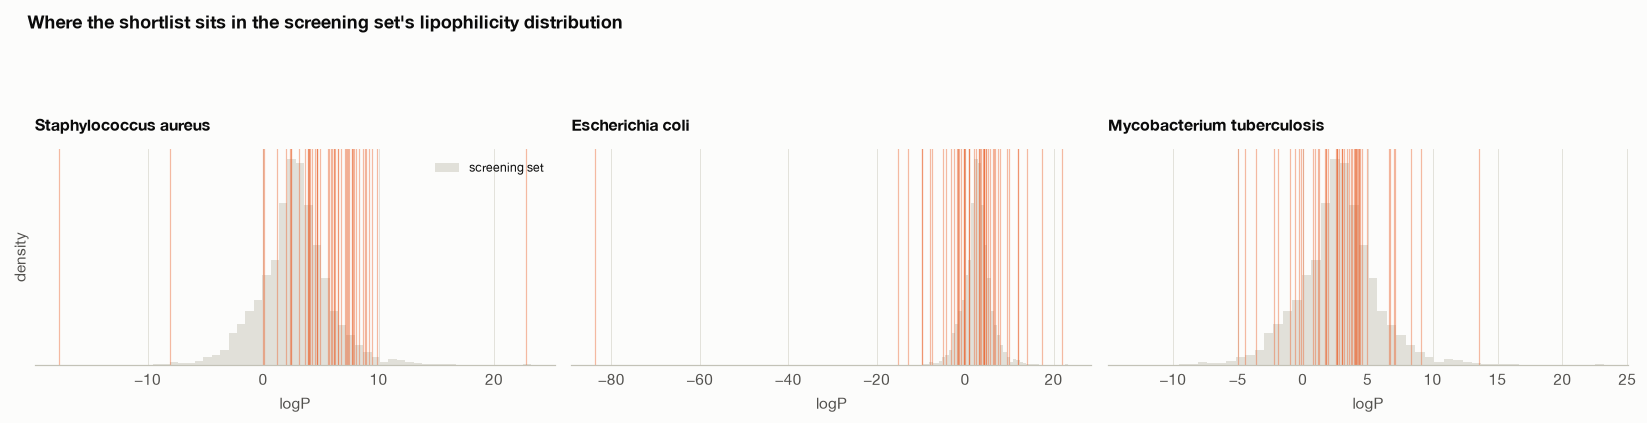

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    ax.hist(screen_logp, bins=50, density=True, color=viz.GRID, label="screening set")
    values = shortlist_logp.get(organism)
    if values is not None and np.isfinite(values).any():
        for value in values[np.isfinite(values)]:
            ax.axvline(value, color=viz.SERIES[1], alpha=0.45, linewidth=0.8)
    ax.set_xlabel("logP")
    ax.set_yticks([])
    ax.set_title(organism, fontsize=10.5)
axes[0].set_ylabel("density")
axes[0].legend(fontsize=8)
fig.suptitle("Where the shortlist sits in the screening set's lipophilicity distribution",
             x=0.02, ha="left", fontweight="bold")
viz.save(fig, "05_promiscuity")
plt.show()

### Does lipophilicity carry a consistent, chemically sensible signal

If a property effect is real it should hold on the large partitions, not only on the small one,
and its sign should make chemical sense. This measures the AUROC of ranking by logP alone on each
partition separately, with intervals, and lets the result say what it says.

A first pass at this claimed a Gram-positive against Gram-negative flip and it did not survive
checking: the apparent *S. aureus* effect existed only on the 1,424-compound holdout and pointed
the other way on the test set. The honest version is below, measured on every partition.

In [17]:
logp_column = featureset.DESCRIPTOR_NAMES.index("logp")
direction_rows = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    bundle = featureset.load(f"03_features_{slug}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    row = {"pathogen": organism}
    for name in ("train", "test", "plant"):
        index = np.where(frame.partition.eq(name).to_numpy())[0]
        values = bundle["descriptors"][index, logp_column].astype(float)
        truth = bundle["label"][index]
        if len(np.unique(truth)) < 2:
            continue
        auroc = models.roc_auc_score(truth, values)
        lo, hi = models.stratified_bootstrap(truth, values, models.roc_auc_score,
                                             repeats=600, seed=CONFIG["seed"])
        row[name] = auroc
        row[f"{name} 95%"] = f"{lo:.3f}-{hi:.3f}"
        row[f"{name} excludes 0.5"] = bool(lo > 0.5 or hi < 0.5)
    direction_rows.append(row)
    del bundle
direction = pd.DataFrame(direction_rows).set_index("pathogen")
display(direction.style.format({c: "{:.3f}" for c in ("train", "test", "plant")}))
print("AUROC above 0.5 means higher logP goes with activity; below 0.5 means lower logP does.")
print("An effect is only worth believing where the interval excludes 0.5 on the large partitions.")

,train,train 95%,train excludes 0.5,test,test 95%,test excludes 0.5,plant,plant 95%,plant excludes 0.5
pathogen,,,,,,,,,
Staphylococcus aureus,0.501,0.496-0.507,False,0.491,0.479-0.503,False,0.627,0.593-0.662,True
Escherichia coli,0.409,0.402-0.416,True,0.351,0.337-0.366,True,0.315,0.246-0.380,True
Mycobacterium tuberculosis,0.549,0.541-0.559,True,0.545,0.524-0.564,True,0.530,0.481-0.579,False


AUROC above 0.5 means higher logP goes with activity; below 0.5 means lower logP does.
An effect is only worth believing where the interval excludes 0.5 on the large partitions.


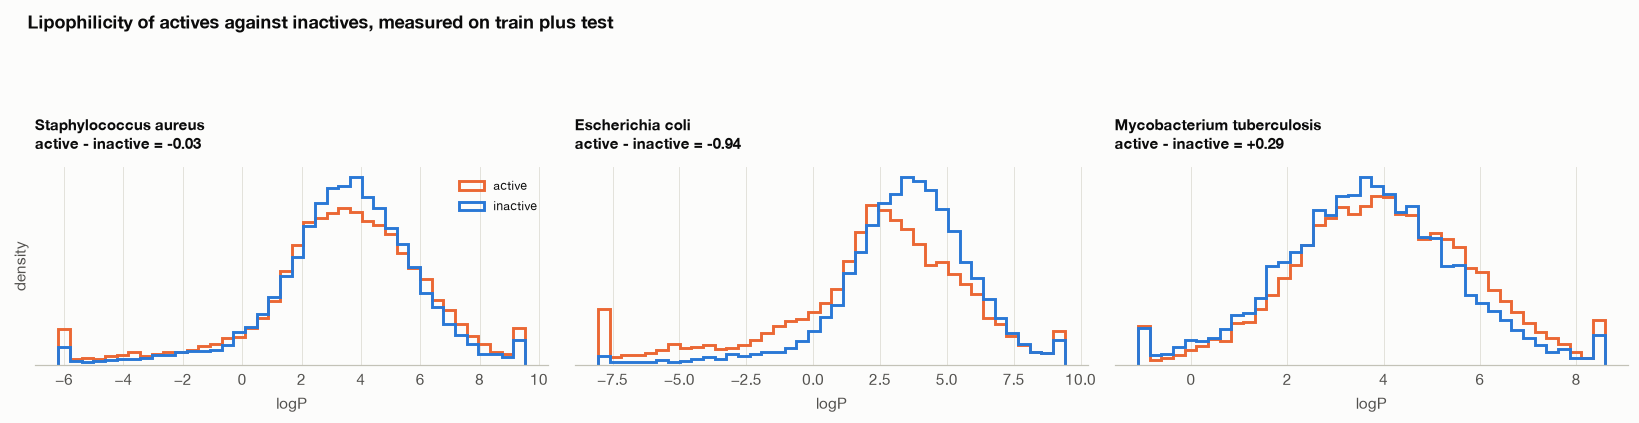

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    slug = curation.slug(organism)
    bundle = featureset.load(f"03_features_{slug}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    index = np.where(frame.partition.isin(["train", "test"]).to_numpy())[0]
    values = bundle["descriptors"][index, logp_column].astype(float)
    truth = bundle["label"][index]
    lo, hi = np.percentile(values, [1, 99])
    for label, colour, name in [(1, viz.SERIES[1], "active"), (0, viz.SERIES[0], "inactive")]:
        ax.hist(np.clip(values[truth == label], lo, hi), bins=40, density=True,
                histtype="step", linewidth=1.9, color=colour, label=name)
    gap = float(np.median(values[truth == 1]) - np.median(values[truth == 0]))
    ax.set_title(organism + chr(10) + f"active - inactive = {gap:+.2f}", fontsize=10)
    ax.set_xlabel("logP")
    ax.set_yticks([])
    del bundle
axes[0].set_ylabel("density")
axes[0].legend(fontsize=8)
fig.suptitle("Lipophilicity of actives against inactives, measured on train plus test",
             x=0.02, ha="left", fontweight="bold")
viz.save(fig, "05_logp_direction")
plt.show()

Measured on the large partitions rather than the holdout, the pattern that survives is a contrast
between the **Gram-negative** and the **mycobacterium**: lower logP goes with activity against
*E. coli*, whose outer membrane favours smaller and more polar compounds, and higher logP goes
with activity against *M. tuberculosis*, whose lipid-rich cell wall favours the opposite. Both
hold on tens of thousands of compounds with intervals excluding chance.

*S. aureus* shows no logP effect worth reporting. An earlier version of this analysis claimed one,
from the holdout alone, and the claim did not survive being checked against the partition where
there was enough data to check it.

### Did the diversity step buy anything

Farthest-point sampling is supposed to spread the shortlist across chemical space. NPClassifier
gives an independent check that costs nothing, because the biosynthetic pathway is already on every
LOTUS record: if the shortlist collapses into one pathway while the pool it came from did not, the
projection is not buying diversity and the honest thing is to say so.

In [19]:
diversity_rows = []
for organism in CONFIG["pathogens"]:
    frame = shortlists[organism]
    share = frame.np_pathway.fillna("(not classified)").value_counts(normalize=True)
    diversity_rows.append({
        "pathogen": organism,
        "distinct pathways in shortlist": int(frame.np_pathway.nunique()),
        "largest pathway share": float(share.iloc[0]),
        "largest pathway": share.index[0],
        "distinct superclasses": int(frame.np_superclass.nunique()),
        "in applicability domain": int(frame.in_applicability_domain.sum()),
    })
diversity = pd.DataFrame(diversity_rows).set_index("pathogen")
display(diversity.style.format({"largest pathway share": "{:.0%}"}))

print("Screening set for comparison:")
print(screen_meta.np_pathway.fillna("(not classified)")
      .value_counts(normalize=True).head(5).mul(100).round(1).to_string())

,distinct pathways in shortlist,largest pathway share,largest pathway,distinct superclasses,in applicability domain
pathogen,,,,,
Staphylococcus aureus,9,34%,Shikimates and Phenylpropanoids,27,50
Escherichia coli,8,37%,Shikimates and Phenylpropanoids,22,50
Mycobacterium tuberculosis,7,37%,Alkaloids,19,50


Screening set for comparison:
np_pathway
Terpenoids                         45.8
Shikimates and Phenylpropanoids    25.5
Alkaloids                          10.4
Polyketides                         5.3
Fatty acids                         4.8


### Why each compound is on the list

A global importance chart says what the model uses on average. It does not let a chemist look at
one row and decide whether to make that compound. For every shortlisted candidate this adds its
three nearest training **actives** with similarities, its strongest SHAP contributions, its
Bemis-Murcko scaffold and the plants it was reported from.

The nearest-actives column is the one to read first and it cuts both ways. A candidate close to a
known active is a credible analogue; a candidate very close to one is barely a new idea. A
candidate far from everything is either genuinely novel or outside the domain, and the distance
column already says which.

In [20]:
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

evidence_frames = {}
for organism in CONFIG["pathogens"]:
    payload = fitted[organism]
    feature_name = payload["feature_set"]
    slug = curation.slug(organism)
    frame = shortlists[organism]
    in_domain = frame[frame.tier.eq("in-domain")].reset_index(drop=True)
    if not len(in_domain):
        continue

    bundle = featureset.load(f"03_features_{slug}")
    splits_frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    train_index = np.where(splits_frame.partition.eq("train").to_numpy())[0]
    actives = train_index[bundle["label"][train_index] == 1]
    train_morgan = featureset.unpack_morgan(bundle["morgan"])[actives]
    labelled = pd.read_parquet(
        data.PROCESSED / f"02_labelled_{slug}.parquet",
        columns=["skeleton", "canonical_smiles"]).set_index("skeleton")

    candidate_table = in_domain[["skeleton", "canonical_smiles"]].assign(
        label=-1, from_plant=True, family=np.nan)
    candidate_bundle = featureset.build(candidate_table, show_progress=False)
    candidate_morgan = featureset.unpack_morgan(candidate_bundle["morgan"])

    inter = candidate_morgan @ train_morgan.T
    union = (candidate_morgan.sum(1)[:, None] + train_morgan.sum(1)[None, :] - inter)
    similarity = inter / np.maximum(union, 1)
    order = np.argsort(-similarity, axis=1)[:, :3]

    explainer = shap.TreeExplainer(payload["model_object"])
    values = explainer.shap_values(
        featureset.matrix(candidate_bundle, feature_name), check_additivity=False)
    if isinstance(values, list):
        values = values[1]
    elif values.ndim == 3:
        values = values[:, :, 1]
    n_desc = len(featureset.DESCRIPTOR_NAMES)
    names = ([f"bit_{i}" for i in range(values.shape[1] - n_desc)] + featureset.DESCRIPTOR_NAMES
             if feature_name == "hybrid" else
             featureset.DESCRIPTOR_NAMES if feature_name == "descriptors" else
             [f"bit_{i}" for i in range(values.shape[1])])

    rows = []
    for i, candidate in in_domain.iterrows():
        neighbours = "; ".join(
            f"{bundle['skeleton'][actives[j]]} ({similarity[i, j]:.2f})" for j in order[i])
        top = np.argsort(-np.abs(values[i]))[:4]
        drivers = "; ".join(f"{names[k]} {values[i, k]:+.3f}" for k in top)
        mol = Chem.MolFromSmiles(candidate.canonical_smiles)
        scaffold = (MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False) or "acyclic"
                    if mol is not None else "")
        rows.append({
            "rank": int(candidate["rank"]) if "rank" in candidate else i + 1,
            "skeleton": candidate.skeleton,
            "score": candidate.ranking_score,
            "nearest training actives": neighbours,
            "top SHAP drivers": drivers,
            "scaffold": scaffold,
            "source plants": candidate.get("source_plants", ""),
        })
    evidence = pd.DataFrame(rows)
    evidence_frames[organism] = evidence
    evidence.to_csv(RESULTS / f"evidence_{slug}.csv", index=False)
    print(f"{organism}: evidence for {len(evidence)} in-domain candidates", flush=True)
    del bundle, train_morgan

example = evidence_frames.get(CONFIG["pathogens"][0])
if example is not None:
    display(example.head(5))

Staphylococcus aureus: evidence for 50 in-domain candidates


Escherichia coli: evidence for 50 in-domain candidates


Mycobacterium tuberculosis: evidence for 50 in-domain candidates


,rank,skeleton,score,nearest training actives,top SHAP drivers,scaffold,source plants
0,1,AOJJSUZBOXZQNB,0.858571,MFLNETBVTFQLMO (0.99); YSTRWQVEZGVBLR (0.85); ...,bit_1763 +5974063775318367.000; heteroatoms +5...,O=C1c2ccccc2C(=O)c2cc3c(cc21)CCCC3OC1CCCCO1,NaN
1,2,XLGPTVJCHRTFPZ,0.818571,LDRMNNNAWXNJNE (0.80); IODGCJOHBKZXSG (0.73); ...,bit_1295 -2166898690293436672.000; bit_1453 -2...,c1cc2cc(c1)Oc1ccc(cc1)CCc1ccccc1-c1ccc(cc1)CC2,Marchantia chenopoda
2,3,PTAOGUZRPGZTHF,0.795714,KEKCCRCHJCRAMG (0.77); UOFVFVZZENGXIU (0.36); ...,bit_1128 -6275762174958613504.000; bit_456 -62...,O=C1CC(c2ccccc2)Oc2c(Cc3cccc(Cc4ccccc4)c3)cc(C...,Piper sarmentosum
3,4,FQQFFZPBGYGDSX,0.781429,HESFZADEDUAEQE (0.73); BEZKVXWUGYBPJM (0.61); ...,bit_1453 -20282308164925576.000; bit_1729 -202...,O=C1CC2CC=CN12,Solanum lycopersicum
4,5,WIPSREYNTQIPPR,0.771429,ZHYHXGNYAUJLON (0.67); MEZORUBSKPDZIK (0.42); ...,bit_271 +88435915049469008.000; bit_1475 +8111...,C1=Cc2c(CCCCCCCCCCC3CCCCN3)cc(CCCCCCCCCC3CCCCN...,Prosopis juliflora


That table is the honest answer to the interpretability criterion. It is also where a chemist will
find the project's weaknesses fastest, which is the point: a row whose nearest training active
sits at 0.9 similarity is a reminder that the model is recalling a series, and a row whose SHAP
drivers are all molecular weight and logP is a reminder of what the artefact check above is for.

### How stable is the shortlist across seeds

Farthest-point sampling starts from a seeded random candidate, so the particular 50 depend on the
seed. Precision at the head of the ranking is the headline metric, so this is worth measuring
rather than asserting: the pool is seed-independent, only which members of it are chosen is not.

In [21]:
stability = []
for organism in CONFIG["pathogens"]:
    payload = fitted[organism]
    scores = screen_scores[organism]
    top = np.argsort(-scores)[: CONFIG["candidate_pool"]]
    train_bundle = featureset.load(f"03_features_{curation.slug(organism)}")
    train_frame = pd.read_parquet(
        data.PROCESSED / f"03_splits_{curation.slug(organism)}.parquet")
    train_morgan = featureset.unpack_morgan(train_bundle["morgan"])[
        np.where(train_frame.partition.eq("train").to_numpy())[0]]
    distance = nearest_tanimoto(screen_morgan[top], train_morgan)
    pool = top[distance >= DOMAIN_CUTOFF]
    picks = [
        set(pool[farthest_point(screen_morgan[pool], CONFIG["shortlist_size"], seed)])
        for seed in range(5)
    ]
    overlaps = [len(a & b) / CONFIG["shortlist_size"]
                for i, a in enumerate(picks) for b in picks[i + 1:]]
    union = set().union(*picks)
    stability.append({
        "pathogen": organism,
        "in-domain pool": len(pool),
        "mean pairwise overlap over 5 seeds": float(np.mean(overlaps)),
        "distinct compounds across 5 seeds": len(union),
        "always chosen": len(set.intersection(*picks)),
    })
    del train_morgan, train_bundle
pd.DataFrame(stability).set_index("pathogen").style.format(
    {"mean pairwise overlap over 5 seeds": "{:.0%}"})

,in-domain pool,mean pairwise overlap over 5 seeds,distinct compounds across 5 seeds,always chosen
pathogen,,,,
Staphylococcus aureus,375,52%,111,14
Escherichia coli,144,79%,76,34
Mycobacterium tuberculosis,166,73%,83,28


The number to read is the pairwise overlap. A high overlap means the diversity step is finding a
genuine spread rather than an arbitrary one, and the shortlist would be much the same whoever ran
it. A low overlap does not invalidate the ranking, which is seed-independent, but it does mean the
specific 50 are one valid sample of the diverse subsets of the pool rather than the diverse subset,
and that is how they should be described to a chemist.

### The assumption this table rests on, and how badly it holds

Sensitivity and specificity cannot be moved by prevalence, which is the usual justification for
transporting them to a new population. That argument is correct and incomplete. Transporting them
also requires the **class-conditional score distributions** to be the same in the new population:
active compounds there must look to the model like active compounds here. That is an assumption
about chemistry, not about arithmetic, and it is testable on the two held-out sets we already have.

In [22]:
transport = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    sets = {n: pd.read_parquet(data.PROCESSED / f"04_scores_{slug}_{n}.parquet")
            for n in ("test", "plant")}
    reference = sets["plant"]
    threshold, _ = models.choose_threshold(
        reference.label.to_numpy(), reference.score_calibrated.to_numpy(), recall_floor=0.40)
    row = {"pathogen": organism, "threshold": threshold}
    for name, frame in sets.items():
        sens, spec = models.operating_rates(
            frame.label.to_numpy(), frame.score_calibrated.to_numpy(), threshold)
        tag = "scaffold test" if name == "test" else "plant holdout"
        row[f"sensitivity, {tag}"] = sens
        row[f"specificity, {tag}"] = spec
    ppv_from = {}
    for name, frame in sets.items():
        sens, spec = models.operating_rates(
            frame.label.to_numpy(), frame.score_calibrated.to_numpy(), threshold)
        ppv_from[name] = models.precision_at_prevalence(sens, spec, 0.10)
    row["PPV at 10% from test"] = ppv_from["test"]
    row["PPV at 10% from plant"] = ppv_from["plant"]
    row["ratio"] = (max(ppv_from.values()) / min(ppv_from.values())
                    if min(ppv_from.values()) > 0 else np.nan)
    transport.append(row)
transport = pd.DataFrame(transport).set_index("pathogen")
display(transport.style.format("{:.3f}"))

,threshold,"sensitivity, scaffold test","specificity, scaffold test","sensitivity, plant holdout","specificity, plant holdout",PPV at 10% from test,PPV at 10% from plant,ratio
pathogen,,,,,,,,
Staphylococcus aureus,0.334,0.826,0.726,0.511,0.805,0.251,0.225,1.113
Escherichia coli,0.246,0.862,0.779,0.405,0.904,0.303,0.320,1.058
Mycobacterium tuberculosis,0.477,0.792,0.683,0.421,0.744,0.217,0.154,1.407


**The assumption fails on our own data.** Sensitivity measured at the same threshold differs
substantially between the two held-out sets, so the same model at the same cut-off recovers a very
different share of the actives depending on which population you ask. Push those through the
formula and the implied precision at an assumed 10% prevalence differs by the ratio in the last
column, purely from the choice of where sensitivity was estimated.

The screening set sits **further out than either**, with a median nearest-neighbour Tanimoto below
the plant holdout's, so the honest expectation is that the true spread is wider than the ratio
shown and in a direction nothing here can measure. We estimate from the plant holdout because it
is the closer of the two to the screening chemistry, not because it is reliable.

This is the same kind of finding as the analogue-proximity result earlier: a number that looks
solid, tested against our own data, and found to depend on something nobody states. It is reported
rather than removed, and it is the reason the yield table is framed as a range to argue with
rather than a forecast.

### Positive control: tetracycline

The shortlist is a list of predictions nobody has tested, which makes it hard to judge. A control
fixes that. Tetracycline is a plant-adjacent natural product with 336 measured MIC rows against
*S. aureus* in ChEMBL, so we know the answer; the model has never seen it, because every compound
with a measurement is excluded from training by construction and from the screen by the
deduplication key.

This is run deliberately and reported as a control, not as a candidate. It is worth saying how it
got here: in the previous version of this notebook tetracycline appeared as the top-ranked
*S. aureus* **candidate**, because the exclusion key did not collapse tautomers and LOTUS stores
the enol while ChEMBL stores the ketone. That was a bug, found in review. The fix removes it from
the screen, and running it back deliberately turns the accident into the strongest check available
here: a model that has never seen tetracycline, asked where it ranks among a hundred thousand
plant compounds against the organism it is actually used against.

In [23]:
CONTROL_SMILES = (
    "CN(C)[C@@H]1C(O)=C(C(N)=O)C(=O)[C@@]2(O)C(O)=C3C(=O)c4c(O)cccc4"
    "[C@@](C)(O)[C@H]3C[C@@H]12"
)
control_skeleton = features.canonical_skeleton(CONTROL_SMILES)
control_mol = features.molecule(CONTROL_SMILES)

control_rows = []
for organism in CONFIG["pathogens"]:
    payload = fitted[organism]
    feature_name = payload["feature_set"]
    bundle = featureset.load(f"03_features_{curation.slug(organism)}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{curation.slug(organism)}.parquet")
    seen = control_skeleton in set(frame.skeleton)

    control_table = pd.DataFrame({
        "skeleton": [control_skeleton], "canonical_smiles": [CONTROL_SMILES],
        "label": [-1], "from_plant": [True], "family": [np.nan],
    })
    control_bundle = featureset.build(control_table, show_progress=False)
    X_control = featureset.matrix(control_bundle, feature_name)
    score = payload["model_object"].predict_proba(X_control)[:, 1][0]

    pool_scores = np.sort(screen_scores[organism])[::-1]
    better = int((pool_scores > score).sum())
    control_rows.append({
        "pathogen": organism,
        "in any partition of this pathogen": seen,
        "raw score": score,
        "compounds scoring higher": better,
        "percentile among the screening set": 1 - better / len(pool_scores),
    })
control = pd.DataFrame(control_rows).set_index("pathogen")
display(control.style.format({"raw score": "{:.3f}",
                              "percentile among the screening set": "{:.4f}"}))
print(f"control skeleton (tautomer-canonical): {control_skeleton}")

,in any partition of this pathogen,raw score,compounds scoring higher,percentile among the screening set
pathogen,,,,
Staphylococcus aureus,False,0.473,13944,0.8573
Escherichia coli,False,0.809,1,1.0000
Mycobacterium tuberculosis,False,0.468,33153,0.6607


control skeleton (tautomer-canonical): ('MUHBBHLZPHKTTR', 'canonical')


**This is precision evidence, not just a sanity check.** The team's decision was precision over
recall, because a false positive spends synthesis and assay money while a false negative costs
nothing when the candidate pool is effectively unlimited. Precision matters only at the head of
the ranking, which is exactly the region a held-out known antibiotic probes. Where a control lands
by percentile is therefore a headline number beside P@10%, not a footnote.

Read it as a single observation, not a performance estimate: one compound, one draw, no
interval. What makes it worth reporting is that it is unfakeable in the direction that matters.
The model could not have memorised tetracycline, and where it places a known antibiotic among a
hundred thousand untested plant compounds is a question with a right answer that we did not
supply.

It is also the right place to note what the control cannot tell us. Tetracycline is a very well
studied scaffold with many analogues in ChEMBL, so a high rank partly reflects familiarity with
its chemical neighbourhood rather than insight about tetracycline itself. The applicability-domain
distance in the table above is the honest measure of that.

### What this costs and returns in a laboratory

Precision measured on the plant holdout is not the precision a laboratory will see, and the reason
is worth stating precisely because it is the opposite of the usual one.

This is **not** a scarce-positive problem. In the measured data actives are close to half of all compounds, and class weighting is
already handled in training through `class_weight="balanced"`; the curation table in 02 gives the
exact rate per pathogen. The difficulty is that the measured population is
more than half active at all, which happens because a compound earns a published MIC when somebody
expected it to work. Reweighting cannot fix that, because it is not an imbalance to correct; it is
a population that does not resemble the one we will deploy on.

The plant holdout inherits the same bias, though less strongly; its base rate is printed in the
results table above. Untested plant chemistry is far sparser in actives than either, and calibration cannot repair a base-rate shift, only a
miscalibrated model. That gap is what the table below is for.

The transfer that can be done honestly uses sensitivity and specificity, which do not depend on
prevalence, and Bayes' rule to get the precision implied at an assumed prevalence. The prevalence
is an assumption and is labelled as one; what the table gives is how the answer changes across a
plausible range, which is more use to someone deciding whether to spend a synthesis budget than a
single precision figure with no prior attached.

In [24]:
PREVALENCES = [0.30, 0.10, 0.05, 0.01]
SYNTHESISED = int(os.environ.get("ETHNOHACK_SYNTHESISED", 20))

economics = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    scored = pd.read_parquet(data.PROCESSED / f"04_scores_{slug}_plant.parquet")
    truth = scored.label.to_numpy()
    probability = scored.score_calibrated.to_numpy()
    threshold, rule = models.choose_threshold(truth, probability, recall_floor=0.40)
    sens, spec = models.operating_rates(truth, probability, threshold)
    for prevalence in PREVALENCES:
        ppv = models.precision_at_prevalence(sens, spec, prevalence)
        lo, hi = models.yield_interval(truth, probability, threshold, prevalence, SYNTHESISED,
                                       repeats=500, seed=CONFIG["seed"])
        spread = float(np.sqrt(SYNTHESISED * ppv * (1 - ppv))) if np.isfinite(ppv) else np.nan
        economics.append({
            "pathogen": organism,
            "assumed prevalence": prevalence,
            "implied precision": ppv,
            f"expected actives in {SYNTHESISED}": ppv * SYNTHESISED,
            "sens/spec sampling interval": f"{lo:.1f} to {hi:.1f}",
            "batch-to-batch sd": spread,
            "a realised batch of 20": f"{max(0, ppv * SYNTHESISED - 2 * spread):.0f} to "
                                      f"{min(SYNTHESISED, ppv * SYNTHESISED + 2 * spread):.0f}",
        })
economics = pd.DataFrame(economics).set_index(["pathogen", "assumed prevalence"])
display(economics.style.format({
    "implied precision": "{:.2f}",
    f"expected actives in {SYNTHESISED}": "{:.1f}",
    "batch-to-batch sd": "{:.2f}",
}))
print("THREE uncertainties, only the smallest of which is an interval here:")
print("  1. sampling error in sensitivity and specificity -> the interval column")
print("  2. which population they were measured on -> see the transport table below, larger")
print("  3. the prevalence assumption itself -> not quantified, probably the largest")
print("The last column is binomial spread: what one actual batch of 20 could return at that")
print("precision, which is wider than any of the above and is what a chemist experiences.")

THREE uncertainties, only the smallest of which is an interval here:
  1. sampling error in sensitivity and specificity -> the interval column
  2. which population they were measured on -> see the transport table below, larger
  3. the prevalence assumption itself -> not quantified, probably the largest
The last column is binomial spread: what one actual batch of 20 could return at that
precision, which is wider than any of the above and is what a chemist experiences.


Read the bottom row as the pessimistic case and the top as the optimistic one. If the table says
that at 5% prevalence a batch of twenty yields a handful of genuine actives, that is a defensible
thing to tell a chemist; if it says fewer than one, the honest conclusion is that the model is not
yet worth a synthesis budget for that pathogen, and saying so is more valuable than a shortlist
that looks confident.

The interval comes from resampling the plant holdout, so it carries the uncertainty in sensitivity
and specificity. It does **not** carry uncertainty in the prevalence assumption, which is likely
the larger of the two. That is why the range of prevalences is shown rather than one number.

**Where we would put our own money: between 1% and 5%, and closer to 1%.** The reasoning, such as
it is. The 30% row is certainly wrong, because it is the holdout's own base rate and that holdout
exists only because somebody already thought those compounds worth testing. Published
whole-library screens of natural-product collections against a single bacterium typically report
hit rates in the low single digits at comparable concentration cut-offs, and our 32 µM threshold
is permissive rather than strict, which pushes the estimate up a little. Against that, the
screening set here is not a curated library: it is every plant structure LOTUS records, including
large numbers of sugars, lipids and ubiquitous primary metabolites that no one would submit to a
screen. That pushes it down, and in our judgement further than the permissive threshold pushes it
up.

Nobody knows this number within an order of magnitude, and we have not measured it. It is stated
so that a reader can disagree with the assumption rather than with a conclusion that hides it.

## 6. The shortlist

**What ships is the in-domain tier.** Precision outside the applicability domain is not
measurable, so a compound the model cannot score cannot be defended on a precision argument, and
the deliverable is a precision argument. `shortlist_<organism>.csv` is what a chemist should work
from. The exploratory compounds are kept, because deleting an inconvenient result is how a
pipeline stops being honest, but they go to `exploratory_<organism>.csv` under their own name and
should be read as prompts for curiosity rather than as candidates.

Diversity selection runs **inside** the in-domain set, so the spread is over compounds we can
actually score rather than over the whole pool.

**What is actually driving the order.** Section 3b compares the model against ranking by a single
physicochemical descriptor. Where the model's advantage over that baseline is small, the shortlist
order is close to a property sort, and a chemist should know that before spending a synthesis slot
confirming that, say, polar compounds inhibit a Gram-negative organism. The per-compound evidence
table is the place to check which it is for any individual row.

**Reading the columns.** `rank` orders the shortlist by `ranking_score`, the raw model score, so
rank 1 is the best-scoring candidate. `selection_order` is the order farthest-point sampling
picked them in, which carries no quality meaning at all: it starts from a seeded random candidate
and then repeatedly takes whichever remaining compound is least similar to everything chosen so
far. It is recorded because it is what produced this particular 50 out of the top
`candidate_pool`, not because a low number is better.

`predicted_probability` is the calibrated probability and it is deliberately coarse, taking only a
handful of distinct values across the 50, so two candidates showing the same probability are in
the same band rather than genuinely tied. `ranking_score` is what separates them.

In [25]:
written = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    frame = shortlists[organism]
    shipped = frame[frame.tier.eq("in-domain")].copy()
    exploratory = frame[frame.tier.eq("exploratory")].copy()
    for part, label in [(shipped, "shortlist"), (exploratory, "exploratory")]:
        part = part.sort_values("ranking_score", ascending=False).reset_index(drop=True)
        part["rank"] = np.arange(1, len(part) + 1)
        path = RESULTS / f"{label}_{slug}.csv"
        part.to_csv(path, index=False)
        if label == "exploratory":
            notice = [
                "EXPLORATORY CANDIDATES, READ BEFORE USE",
                "",
                f"Pathogen: {organism}",
                f"File: {path.name}",
                "",
                "These compounds sit OUTSIDE the model's applicability domain: their nearest",
                "training compound is further away than the 25th percentile of the plant",
                "holdout, which is the most distant set on which performance was measured.",
                "",
                "The scores in that file are NOT evidence of activity and must not be read as",
                "a ranking of candidates. They are published so that nothing was quietly",
                "deleted, not because they are actionable.",
                "",
                f"Applicability-domain cutoff: Tanimoto {DOMAIN_CUTOFF:.3f}",
                "The shortlist a chemist should work from is shortlist_<organism>.csv.",
            ]
            (RESULTS / f"{label}_{slug}.README.txt").write_text(chr(10).join(notice) + chr(10))

        written.append({"pathogen": organism, "table": label, "compounds": len(part),
                        "path": str(path.relative_to(ROOT))})

    entry = ledger.record(
        f"shortlist_{slug}",
        {
            "task": f"{organism} MIC, whole organism",
            "model": fitted[organism]["model"],
            "feature_set": fitted[organism]["feature_set"],
            "screening_set": "LOTUS plant compounds, deduplicated by InChIKey skeleton, "
                             "never measured against the three pathogens",
            "candidate_pool": CONFIG["candidate_pool"],
            "shortlist_size": CONFIG["shortlist_size"],
            "diversity": "farthest-point sampling on Morgan fingerprints",
            "in_domain_tanimoto": DOMAIN_CUTOFF,
        },
        {
            "screened": len(screen_bundle["skeleton"]),
            "shortlisted_in_domain": int(frame.tier.eq("in-domain").sum()),
            "exploratory": int(frame.tier.eq("exploratory").sum()),
            "median_shortlist_probability": float(frame.predicted_probability.median()),
            "median_shortlist_tanimoto": float(frame.nearest_training_tanimoto.median()),
            "in_domain": int(frame.in_applicability_domain.sum()),
            "distinct_pathways": int(frame.np_pathway.nunique()),
            "plant_auroc": headline.loc[(organism, "plant holdout"), "AUROC"],
            "test_auroc": headline.loc[(organism, "scaffold test"), "AUROC"],
        },
        note="notebook 05 shortlist",
    )
    print(f"{organism}: ledger {entry['id']}")
display(pd.DataFrame(written).set_index(["pathogen", "table"]))

preview = shortlists[CONFIG["pathogens"][0]]
preview = preview[preview.tier.eq("in-domain")].head(10).copy()
preview["canonical_smiles"] = preview.canonical_smiles.str.slice(0, 44) + "..."
preview[["rank", "selection_order", "skeleton", "canonical_smiles", "ranking_score",
         "predicted_probability", "nearest_training_tanimoto", "in_applicability_domain",
         "np_pathway"]]

Staphylococcus aureus: ledger 2026-11-05T03:15:27_shortlist_staphylococcus_aureus


Escherichia coli: ledger 2026-11-05T03:15:27_shortlist_escherichia_coli


Mycobacterium tuberculosis: ledger 2026-11-05T03:15:27_shortlist_mycobacterium_tuberculosis


compounds                                               path
pathogen                   table                                                                    
Staphylococcus aureus      shortlist           50        results/shortlist_staphylococcus_aureus.csv
                           exploratory         15      results/exploratory_staphylococcus_aureus.csv
Escherichia coli           shortlist           50             results/shortlist_escherichia_coli.csv
                           exploratory         15           results/exploratory_escherichia_coli.csv
Mycobacterium tuberculosis shortlist           50   results/shortlist_mycobacterium_tuberculosis.csv
                           exploratory         15  results/exploratory_mycobacterium_tuberculosis...

,rank,selection_order,skeleton,canonical_smiles,ranking_score,predicted_probability,nearest_training_tanimoto,in_applicability_domain,np_pathway
0,1,24,AOJJSUZBOXZQNB,C[C@H]1[C@H]([C@H](C[C@@H](O1)O[C@H]2C[C@@](...,0.858571,0.909247,0.986111,True,Polyketides
1,2,37,XLGPTVJCHRTFPZ,COC1=C2C=C(CCC3=CC(=C(C=C3)C4=C(CCC5=CC=C(O2...,0.818571,0.885821,0.800000,True,Shikimates and Phenylpropanoids
2,3,42,PTAOGUZRPGZTHF,C1[C@H](OC2=C(C=C(C(=C2C1=O)O)CC3=C(C=CC(=C3...,0.795714,0.870188,0.771930,True,Shikimates and Phenylpropanoids
3,4,19,FQQFFZPBGYGDSX,C[C@@H]([C@H]1[C@H]2CC(=C(N2C1=O)C(=O)O)S/C=...,0.781429,0.859517,0.733333,True,Amino acids and Peptides
4,5,10,WIPSREYNTQIPPR,C[C@H]1[C@H](CC[C@H](N1)CCCCCCCCCCC2=C3C=CC[...,0.771429,0.851619,0.666667,True,Alkaloids
5,6,8,HSBRPMSGTJDHMH,CC1=CC2=C(C(=C1)O)C(=O)C3=C(C(=C(C=C3C2)OC)C...,0.735714,0.820396,0.522388,True,Polyketides
6,7,28,GDSPNUSHQQYFSK,C[C@]1(CC[C@@H]2[C@@H]([C@@H]3[C@H]1C[C@@H](...,0.734286,0.819046,0.364486,True,Terpenoids
7,8,17,UOJVSXNASPZQFU,CC1C(C(OC1C2=CC(=C(C=C2)OCCC(C3=CC(=C(C=C3)O...,0.722857,0.807964,0.444444,True,Shikimates and Phenylpropanoids
8,9,49,CJKYODJTBJDEJI,C[C@@H]1CC2=C(C(=C3C(=C2)C=C(C(=C3O)C4=C(C5=...,0.711429,0.796372,0.666667,True,Polyketides
9,10,18,LSHJMDWWJIYXEM,CCCCCC=CCC=CCCCCCCCC(=O)OCC(COP(=O)(O)OCC(CO...,0.705714,0.790383,0.606557,True,Fatty acids


## 7. What this does not support

**These are computational predictions, not evidence of activity.** Every compound on every
shortlist in this notebook is a structure that a model scored highly. Not one of them has been
tested against any bacterium by us. A high score is a reason to put a compound in a plate; it is
not a finding, not a claim of efficacy, and not a statement that the plant it comes from treats
any infection.

**Nothing here is medical advice and nothing here implies a dose.** The pipeline never handles
dosing, formulation, route, toxicity or human exposure, and the one compound property closest to
safety, haemolysis, is absent from the data entirely. Traditional use of a plant is how LOTUS came
to record its chemistry; it is not evidence that the plant, the extract or the compound treats
anything, and this notebook should never be cited as if it were.

**The honest performance number is the plant holdout, and it is modest.** 0.61 to 0.66 AUROC
depending on pathogen. The higher scaffold-split figure is partly an artefact of analogue
proximity, which section 2 sets out with the measurement behind it. Ranking at that level is
useful for ordering a synthesis queue and useless as a yes-or-no verdict on any single compound.

**Most of the screening set is outside the applicability domain.** The cutoff is derived rather
than chosen: it is the 25th percentile of the nearest-neighbour distribution of the plant holdout,
the most distant set on which we have a real performance number. Candidates below it carry an
out-of-domain flag and their scores should be read as little better than a guess, because the
model has seen nothing like them. The flag is in the output table for every candidate, not as a
summary.

### Limitations we measured rather than guessed at

- **Labels pool assay conditions.** ChEMBL reports MICs from different media, inocula, incubation
  times and bacterial strains, and the threshold is applied to all of them alike. A real MIC moves
  several-fold between protocols, so a compound labelled near the threshold is far less certain
  than one far from it, and nothing downstream models that uncertainty.
- **The positive class reflects publication bias.** Close to half of all measured compounds are
  labelled active, which is not what a screening library looks like; notebook 02 gives the exact
  rate per pathogen. Compounds get published MICs
  because somebody expected them to work. The model therefore learns what gets tested and reported
  as much as what works, and that is the strongest reason to read precision at the head of the
  ranking rather than accuracy.
- **Between about 37% and 46% of the negative class rests on censored measurements alone**,
  depending on the pathogen: compounds only ever reported as inactive above some concentration,
  with no exact value anywhere. They are real measurements of failure and dropping them would
  destroy the negative class, but they carry less information than an exact number, and a model
  trained on them partly learns the concentrations people chose to test at. Notebook 02 section 4
  has the per-pathogen table.
- **The plant-compound link is literature-derived.** LOTUS records that a structure was reported
  from an organism. It does not say in what quantity, in which tissue, or whether the compound
  survives any preparation a person would actually use.
- **The model recovers known promiscuous actives, and cannot help doing so.** Some shortlisted
  compounds are fingerprint-identical to training compounds, because a Morgan fingerprint at
  radius 2 cannot tell a C9 alkyl chain from a C12 one. The series this surfaces most strongly is
  quaternary ammonium surfactants, which disrupt membranes indiscriminately and are the classic
  thing to discard from a screen rather than pursue. The flag is in the output table.
- **Whole-organism activity says nothing about mechanism.** 99.6% of our labels are growth
  inhibition of a living bacterium, so the models cannot say which protein a compound acts on, and
  no claim about mechanism should be read out of their feature importances.
- **Single compounds, not extracts.** Traditional plant medicine uses mixtures, and synergy
  between constituents is the part of the Track 2 brief that makes plant medicine interesting. It
  is not measurable from anything in this dataset and we have not attempted it.

### What would have to happen next

Broth microdilution MICs on the shortlisted compounds against the three pathogens, with a
haemolysis counter-screen, run by people with a laboratory. Until then the honest description of
this work is a ranked hypothesis list with its uncertainty attached, which is what the output
tables contain.

### Provenance

ChEMBL (CC BY-SA 3.0) for measured activity, LOTUS (CC0) for plant-compound occurrences, and the
GBIF backbone for the taxonomy that separates plants from fungal and bacterial metabolites. Every
figure in this notebook regenerates from `scripts/` plus notebooks 01 to 05, every run is recorded
in `results/LEDGER.md` with the commit and config behind it, and no data is committed to the
repository. Generative AI assistance was used throughout the build and is disclosed in the README.